In [1]:
# import numpy as np
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# --------------------------------- Internal imports --------------------------------- #
from radiopyo.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo.sim_env import SimEnv
from radiopyo.sim_hand import UnitCell, SimChunksIter
import radiopyo as rp

In [2]:
import ipywidgets as widgets
from IPython.display import display

In [3]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

## Prepare Sim Env

In [4]:
file = Path(rf"{rp.__path__[0]}\data\reactions_Labarbe.toml")
#beam = ConstantBeam(1e3, max_dose=10)
#beam = PulsedBeam(1000, max_dose=13, period=0.5, on_time=500e-6)
#beam = PulsedBeam.from_peak_dose_rate(1000, period=10, on_time=1e-3, max_dose=13)
#sim = UnitCell(file, beam=beam)
uc = UnitCell.from_toml(file)

2023-05-10 17:17:12,470::radiopyo::INFO::Loading config from TOML file: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\reactions_Labarbe.toml
2023-05-10 17:17:12,480::radiopyo::INFO::File is loaded
2023-05-10 17:17:12,481::radiopyo::INFO::Beam configuration detected in config file
2023-05-10 17:17:12,482::radiopyo::INFO::Beam ConstantBeam(dose_rate=1e+07, max_dose=10) is setup
2023-05-10 17:17:12,482::radiopyo::INFO::CONFIG::Configuring Simulation Environment
2023-05-10 17:17:12,483::radiopyo::INFO::CONFIG::3 Acid/Base reactions added
2023-05-10 17:17:12,484::radiopyo::INFO::CONFIG::38 K-reactions added
2023-05-10 17:17:12,485::radiopyo::INFO::CONFIG::1 Enzymatic reactions added
2023-05-10 17:17:12,486::radiopyo::INFO::CONFIG::6 Radiolytic reactions added
2023-05-10 17:17:12,487::radiopyo::INFO::CONFIG::19 Dynamical Species added.
2023-05-10 17:17:12,487::radiopyo::INFO::CONFIG::9 Constant Species added.
2023-05-10 17:17:12,488::radiopyo::INFO::CONFIG::Simulation Configuration don

In [5]:
from scipy.constants import Avogadro  # type: ignore[import]
cell_memb_th = 10e-9 # Cell membrane thickness
cell_rad = 20e-6 # cell radius in µm
cell_surf = 4 * np.pi * cell_rad * cell_rad
cell_vol = cell_surf * cell_rad / 3
O2_diff = 1.7e-5*1e-4 # m²/s
O2_diff / cell_memb_th * cell_surf * Avogadro * 1e3 / cell_vol

1.5356458937999998e+31

In [12]:
O2_diff / cell_vol / cell_memb_th

5073063811054.163

In [6]:
uc.mat["O2_mat"][1][9] - uc.mat["O2_mat"][0][9]

248580126741654.03

In [5]:
uc.mat["O2_mat"]

(array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 1.53564589e+31, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00]),
 array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 7.67822947e+32, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.0000

## Run Sim

In [ ]:
res = uc.prepare_chunked_run(t_span=[1e-9, 500],
                             max_step_size_on=1e-8,
                             max_step_size_off=0.01,
                            ).run()

2023-05-10 17:18:02,967::radiopyo::INFO::Simulation divided in 2 chunks
2023-05-10 17:18:02,970::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

In [7]:
df = res.to_pandas()

### Constant Beam

In [6]:
uc.set_beam(ConstantBeam(1e7, max_dose=10))

chunks = sim.beam.make_time_intervals(start=1e-9,stop=500)
chunks[np.where(chunks[:,1]>0)[0], 1] = sim.beam.timer.on_time / 1e3
chunks[np.where(chunks[:,1]==0)[0], 1] = (sim.beam.timer.period-sim.beam.timer.on_time) / 1e2
if chunks[-1,0] > sim.beam.time_at_max_dose:
    chunks[-2:,1] = 0.1 
    
to_run = sim.prepare_chunked_run(chunks[:,0], max_step=chunks[:,1], use_jac=True, method="LSODA", atol=1e-10)
for sol in tqdm(to_run):
    pass
df = SimUtils.to_pandas(sim, sol)
df[df<0] = 0

  0%|          | 0/2 [00:00<?, ?it/s]

### Pulsed Beam

### Chunked Pulsed Beam

In [52]:
sim.set_beam(PulsedBeam.from_peak_dose_rate(750, period=3e-3, on_time=1e-3, max_dose=10))
chunks = sim.beam.make_time_intervals(start=1e-9,stop=500)
chunks[np.where(chunks[:,1]>0)[0], 1] = sim.beam.timer.on_time / 1e4
chunks[np.where(chunks[:,1]==0)[0], 1] = (sim.beam.timer.period-sim.beam.timer.on_time) / 1e2
if chunks[-1,0] > sim.beam.time_at_max_dose:
    chunks[-2:,1] = 0.01 
to_run = sim.prepare_chunked_run(chunks[:,0], max_step=chunks[:,1], use_jac=True, method="LSODA", atol=1e-10)
for sol in tqdm(to_run):
    pass
print(f"Total simulation time: {sum(sol.exec_time):.3f} s")
df = SimUtils.to_pandas(sim, sol)
df[df<0] = 0

  0%|          | 0/28 [00:00<?, ?it/s]

Total simulation time: 44.496 s


## Plot

In [8]:
RIGHT_LIMIT = 1e3

### Water-only Radiolytic produced species

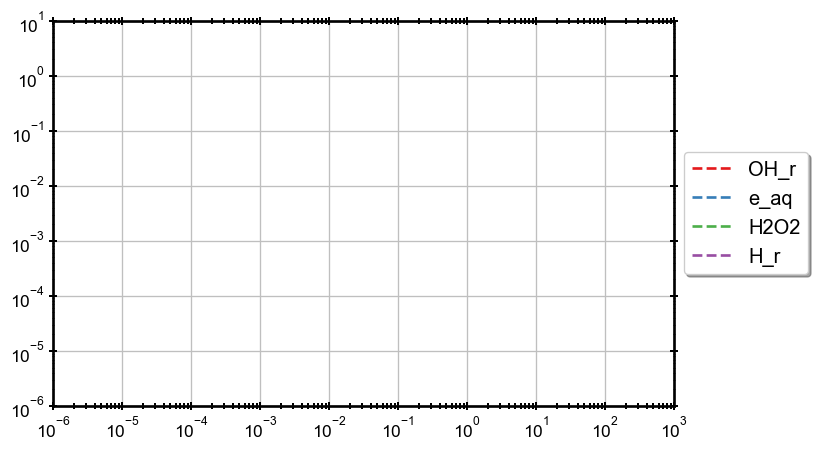

In [9]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]
with fig_man.open(f"CC of G species") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")
    
    ax.set_ylim(bottom=1e-6, top=10)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    RPlot.set_legend_right(ax)

## Plot

In [ ]:
RIGHT_LIMIT = 1e3

### Water-only Radiolytic produced species

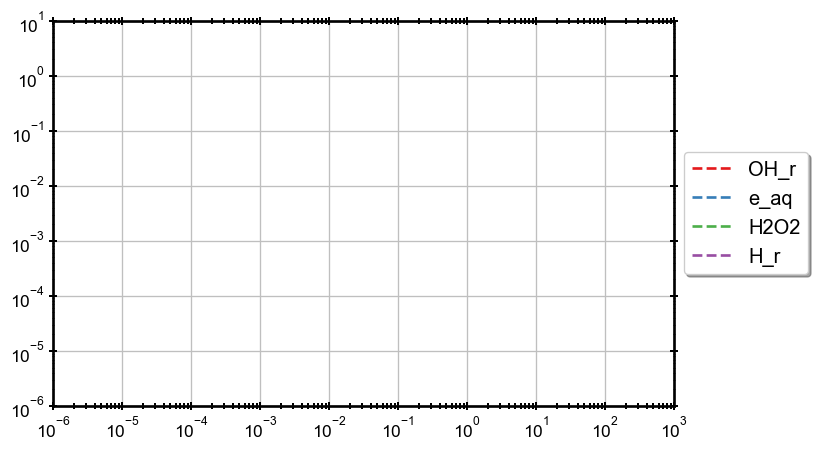

In [ ]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]
with fig_man.open(f"CC of G species") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")
    
    ax.set_ylim(bottom=1e-6, top=10)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    RPlot.set_legend_right(ax)

### Biologicaly relevant species (Beam ON dependant)

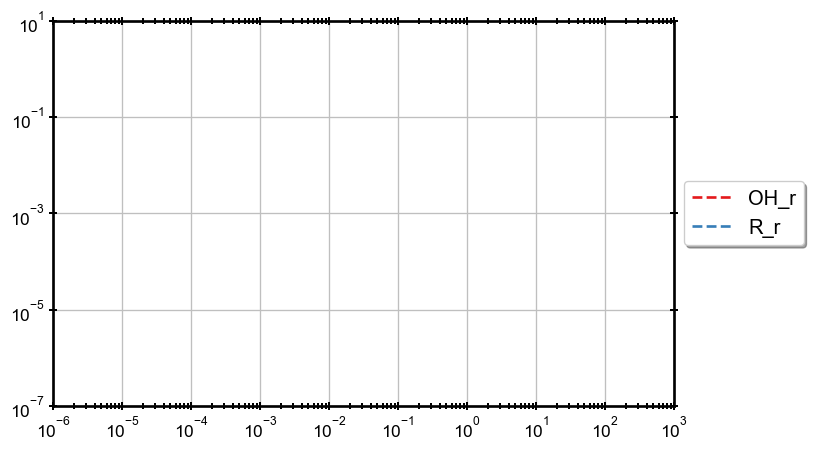

In [10]:
G_species = ["OH_r", "R_r"]
with fig_man.open(f"Beam dep Bio Relevat CC") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")
    
    ax.set_ylim(bottom=1e-7, top=10)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    RPlot.set_legend_right(ax)

### Biologicaly relevant species (Beam ON INdependant)

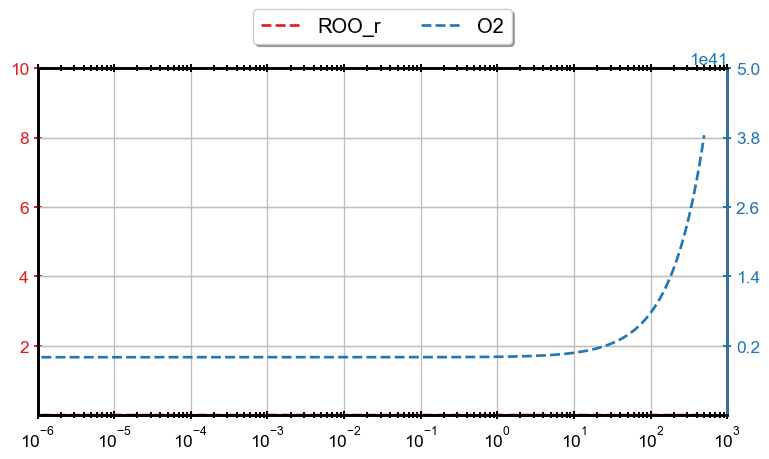

In [11]:
G_species = ["O2", "ROO_r"]
with fig_man.open(f"Beam indep Bio Relevat CC") as (fig, ax):
    
    l, = ax.plot(df.index, df["ROO_r"], label="ROO_r", marker="")
    RPlot.color_ax(ax, color=l.get_color())
    
    ax2 = ax.twinx()
    RPlot.jump_color(ax2, n=0)
    l, = ax2.plot(df.index, df["O2"], label="O2", marker="")
    RPlot.color_ax(ax2, color=l.get_color())
    
    ax.set_ylim(bottom=1e-7, top=10)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    RPlot.adapt_yticks(ax, ax2)
    RPlot.set_legend_top(ax, *RPlot.legendary(ax, ax2))

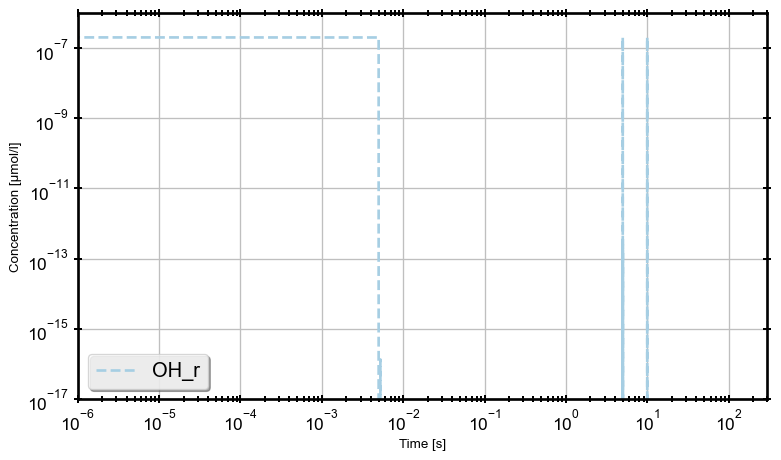

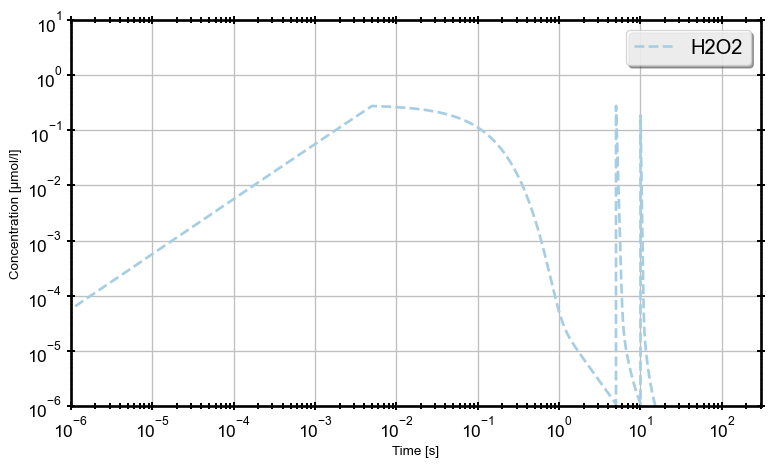

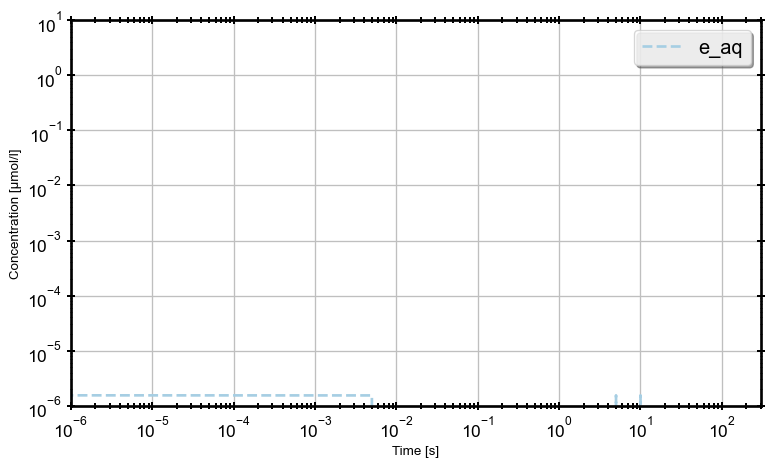

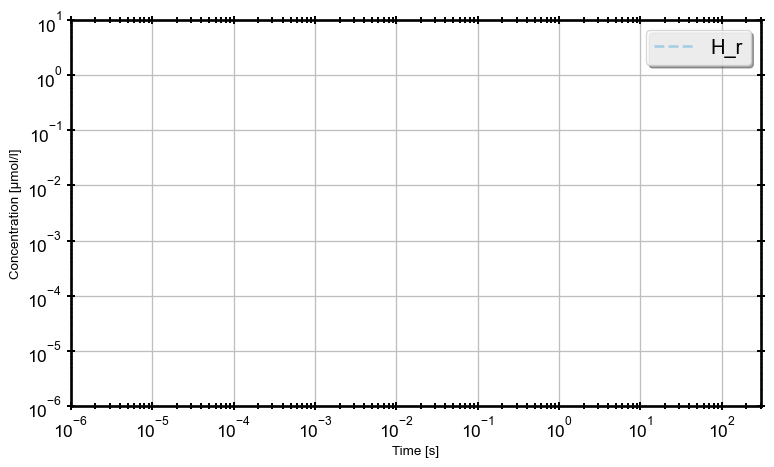

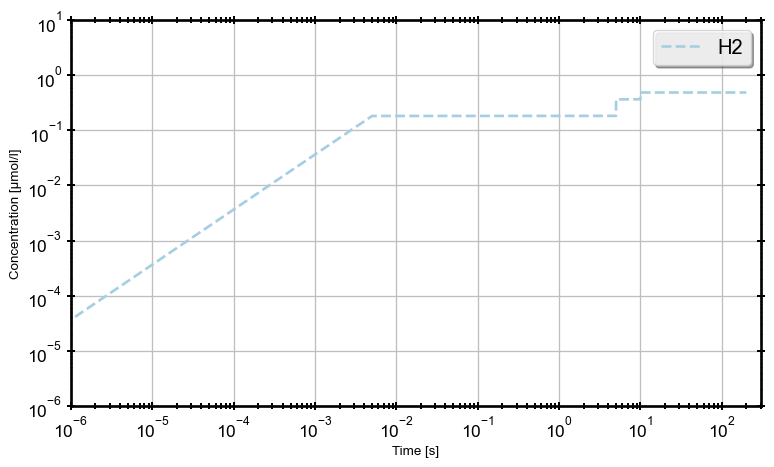

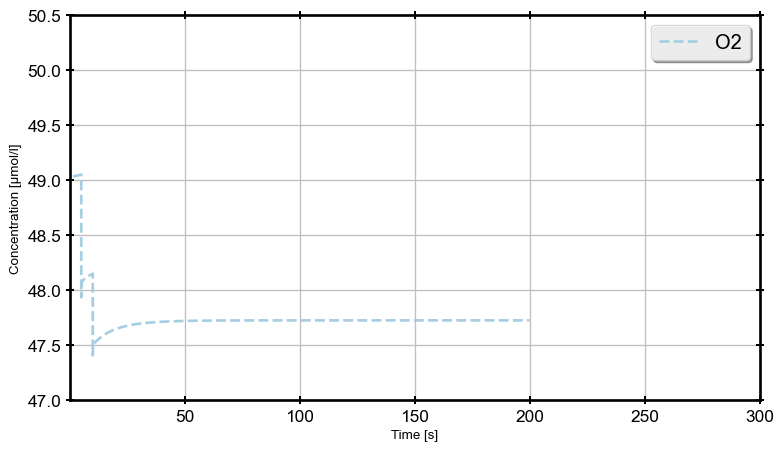

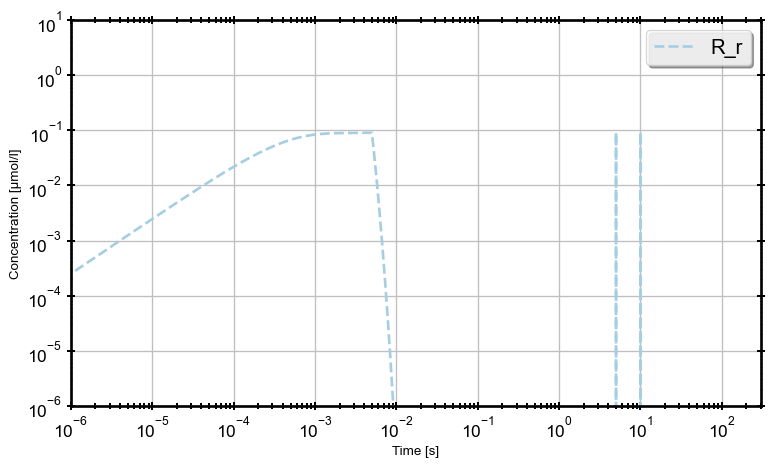

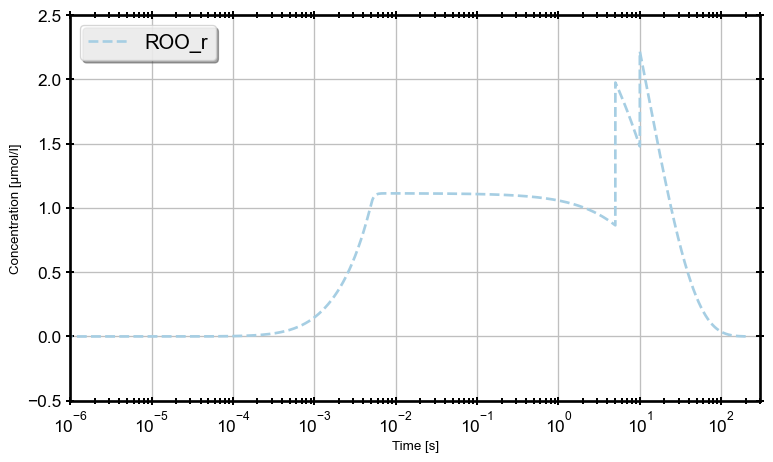

In [16]:
for (label, sp) in zip(sim.env.species_labels(), res):
    if label not in ["OH_r", "H2O2", "e_aq", "H_r", "O2", "H2", "R_r", "ROO_r"]:
        continue
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        #sp = sp * 1e6
        if label=="O2":
            ax.plot(sim_t , sp , label=label, marker="")
            ax.set_xlim(left=1e-6, right=300)
            #ax.set_xscale("log")
            #ax.set_ylim([49.9, 50.01])
        elif label=="ROO_r":
            ax.plot(sim_t, sp, label=label, marker="")
            #ax.set_ylim([0, 3])
            ax.set_xlim(left=1e-6, right=300)
            ax.set_xscale("log")
        elif label=="OH_r":
            ax.plot(sim_t, sp, label=label, marker="")
            #ax.set_ylim([0, 3])
            ax.set_xlim(left=1e-6, right=300)
            ax.set_xscale("log")
            ax.set_yscale("log")
        else:
            ax.plot(sim_t , sp , label=label, marker="")
            ax.set_ylim(bottom=1e-6, top=10)
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_xlim(left=1e-6, right=300)
        ax.legend(loc='best')
        
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Old way of running sim

In [26]:
beam = ConstantBeam(1, max_dose=10)
kwargs = {}
if isinstance(beam, ConstantBeam):
    kwargs["max_step"] = np.inf
else:
    kwargs["max_step"] = beam.timer.on_time/10
    
kwargs["first_step"] = 1e-15
kwargs["atol"] = 1e-15
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
t_span = [1e-9, 500]
tlog = np.arange(-9, -2.9, step=0.1)
tspan = np.power(10, tlog)
tspan = np.append(tspan, np.arange(2e-3, t_span[1], step=1e-3))
y0 = sim.env.initial_values()
ab_mat = sim.env.make_acidBase_matrix()
ki_mat = sim.env.make_kreaction_matrix()
Gi_mat = sim.env.make_radiolytic_vector()
Enzi   = sim.env.make_enzymatic_matrix()

In [27]:
print(f"Running simulation at {beam.dose_rate} Gy/s", end="")
t0 = time.time()
sol = solve_ivp(derive,
                t_span,
                y0,
                args=(beam, ab_mat, ki_mat, Gi_mat, Enzi),
                t_eval=tspan,
                #jac=jac,
                **kwargs)
t1 = time.time()

sim_t, res = sol.t, sol.y
print(f"\t==> Execution time was {t1-t0:.3f} s")


Running simulation at 1 Gy/s	==> Execution time was 0.698 s


### Plot

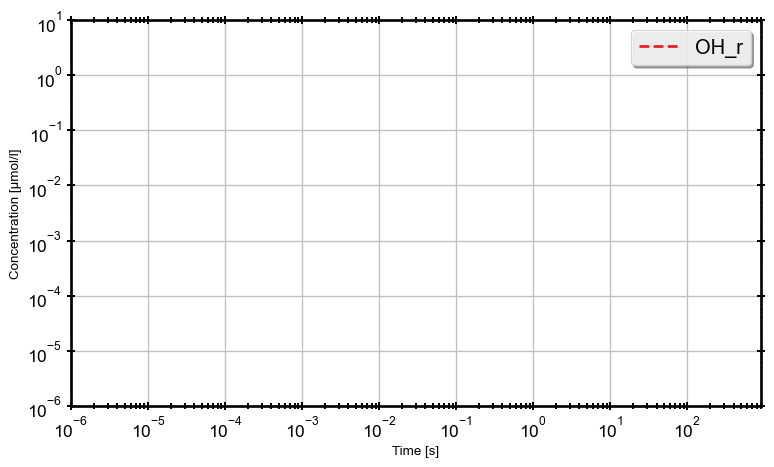

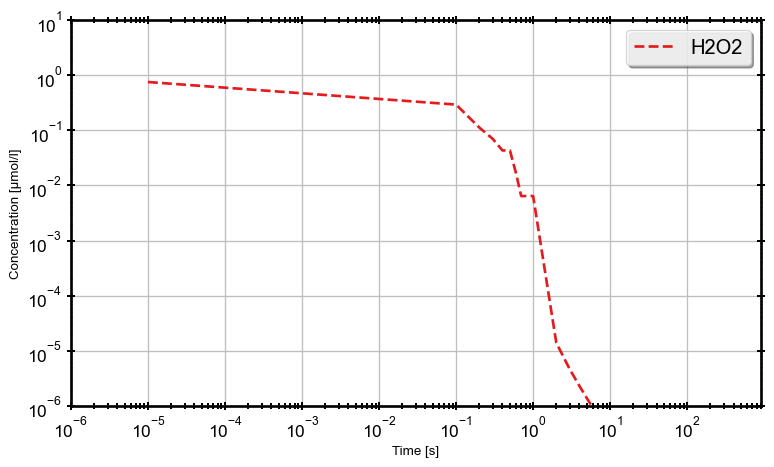

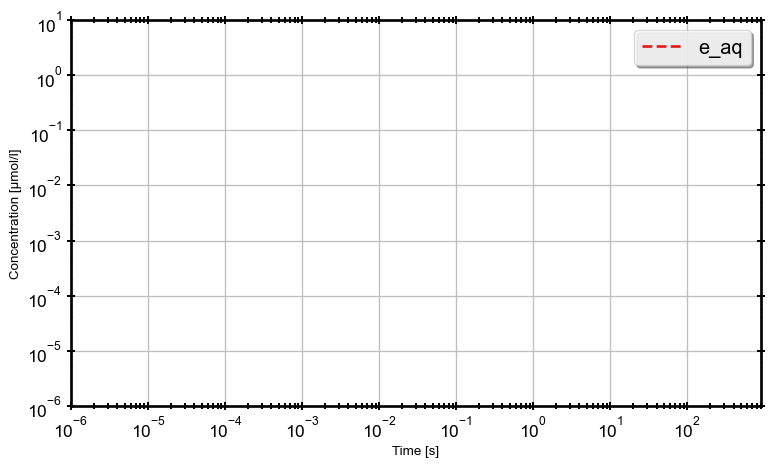

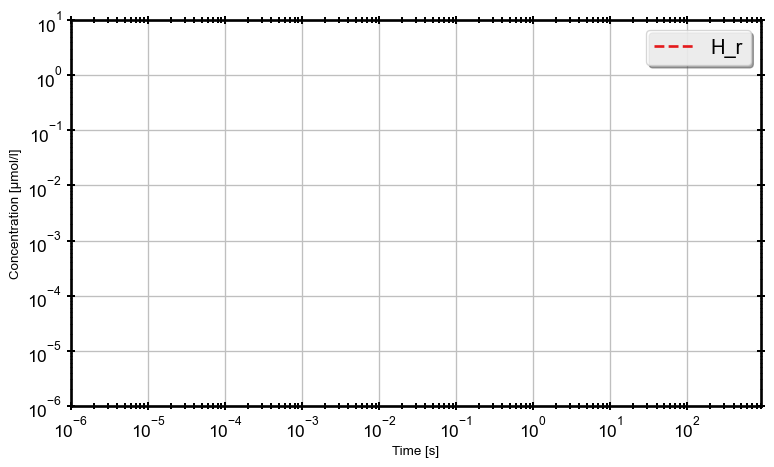

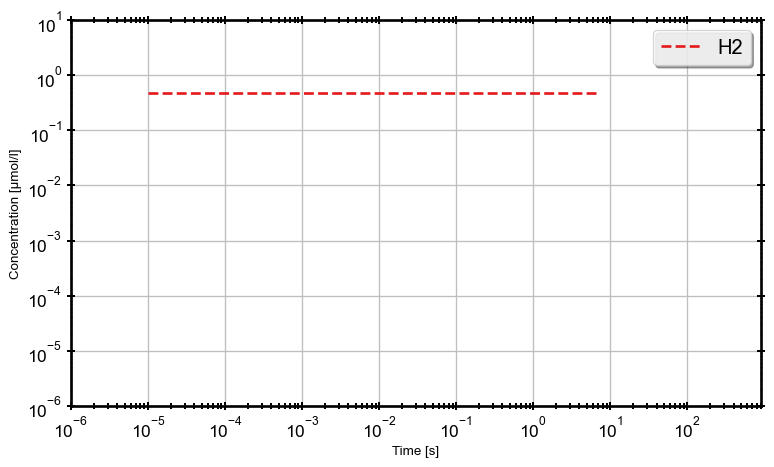

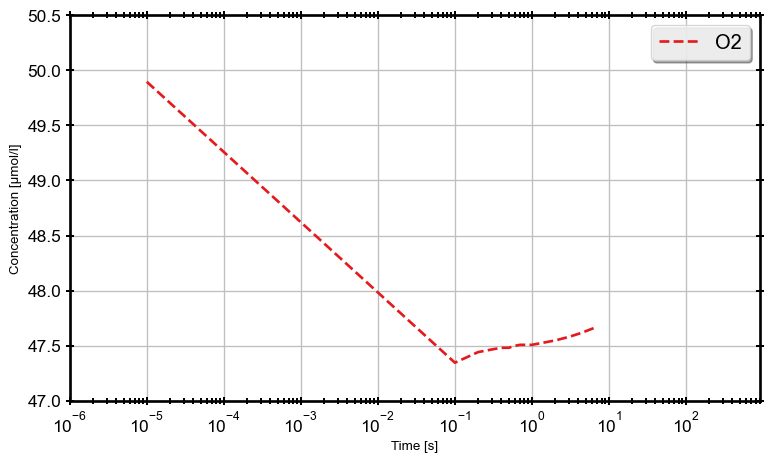

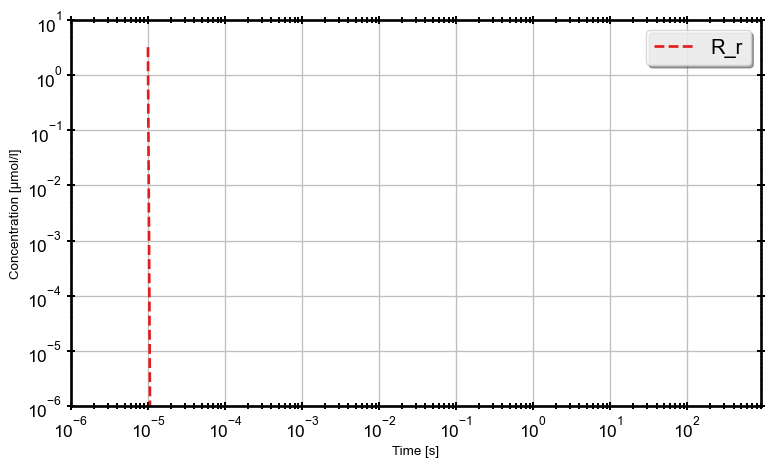

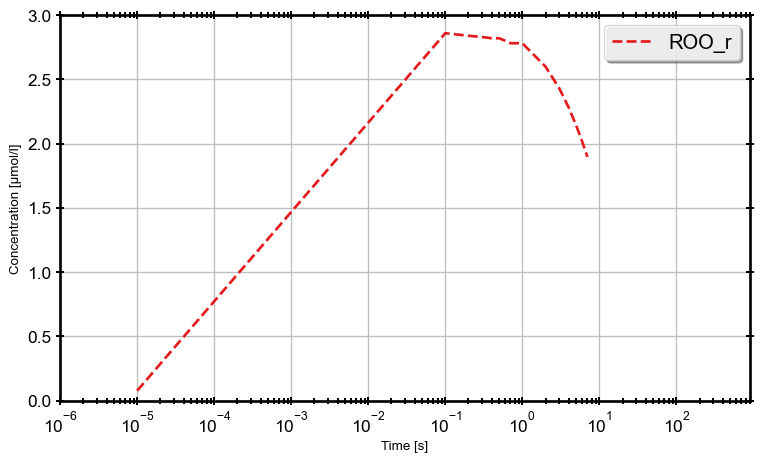

In [12]:
for (label, sp) in zip(sim.env.species_labels(), res):
    if label not in ["OH_r", "H2O2", "e_aq", "H_r", "O2", "H2", "R_r", "ROO_r"]:
        continue
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        #sp = sp * 1e6
        if label=="O2":
            ax.plot(sim_t , sp , label=label, marker="")
            ax.set_xlim(left=1e-6, right=900)
            ax.set_xscale("log")
            #ax.set_ylim([49.9, 50.01])
        elif label=="ROO_r":
            ax.plot(sim_t, sp, label=label, marker="")
            ax.set_ylim([0, 3])
            ax.set_xlim(left=1e-6, right=900)
            ax.set_xscale("log")
        else:
            ax.plot(sim_t , sp , label=label, marker="")
            ax.set_ylim(bottom=1e-6, top=10)
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_xlim(left=1e-6, right=900)
        ax.legend(loc='best')
        
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Explore reaction Rates:

In [7]:
df_r = SimUtils.reconstruct_reactions(sim, sol)
df_b = SimUtils.species_balance_evolution(sim, sol)
#df_j = SimUtils.reconstruct_jacobian(sim, sol)

In [22]:
df_b

,OH_r,O_r_minus,H2O2,HO2_minus,HO2_r,O2_r_minus,e_aq,H_r,H2,O2,O2_minus_minus,O3_minus,Fe_plus_plus_plus,HO_r,RH_r,R_r,ROO_r,ROH,RO,ROOH
1.000000e-09,2.901996,0.000000e+00,7.565917e-01,0.000000e+00,0.000000e+00,0.000000e+00,2.901996,0.642585,0.487121,0.000000e+00,0.000000e+00,0.000000e+00,0.04895,0.04895,0.000000,6.114919e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1.001000e-09,2.898908,-3.607362e-09,7.565917e-01,-4.815085e-19,6.746458e-07,2.756507e-06,2.901587,0.642520,0.487121,-3.432692e-06,1.284053e-19,6.569034e-12,0.04895,0.04895,0.000659,6.143908e-01,1.535977e-09,1.179624e-38,1.179624e-38,3.071969e-26
1.002000e-09,2.895824,-7.210887e-09,7.565917e-01,-1.925293e-18,1.349223e-06,5.512626e-06,2.901178,0.642455,0.487121,-6.864934e-06,7.703432e-19,1.313108e-11,0.04895,0.04895,0.001318,6.172866e-01,3.079193e-09,1.064997e-37,1.064997e-37,9.230371e-26
1.026698e-09,2.820643,-9.505639e-08,7.565917e-01,-3.399817e-16,1.798936e-05,7.346570e-05,2.891095,0.640854,0.487121,-9.149851e-05,1.221235e-15,1.730984e-10,0.04895,0.04895,0.017505,6.878790e-01,4.337336e-08,1.671919e-33,1.671919e-33,1.156519e-23
1.051397e-09,2.747414,-1.806213e-07,7.565917e-01,-1.248174e-15,3.458802e-05,1.411826e-04,2.881048,0.639257,0.487121,-1.758588e-04,8.672185e-15,3.289126e-10,0.04895,0.04895,0.033535,7.566388e-01,8.796973e-08,2.420481e-32,2.420481e-32,4.400437e-23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1.496672e+02,0.000000,0.000000e+00,-1.871785e-17,0.000000e+00,0.000000e+00,-2.542039e-14,0.000000,0.000000,0.000000,2.549063e-13,0.000000e+00,0.000000e+00,0.04895,0.04895,0.000000,1.373555e-13,-2.808142e-10,2.358316e-13,2.358316e-13,1.373555e-13
1.497672e+02,0.000000,0.000000e+00,-1.867816e-17,0.000000e+00,0.000000e+00,-2.538446e-14,0.000000,0.000000,0.000000,2.529587e-13,0.000000e+00,0.000000e+00,0.04895,0.04895,0.000000,1.367950e-13,-2.796665e-10,2.339110e-13,2.339110e-13,1.367950e-13
1.498672e+02,0.000000,0.000000e+00,-1.863858e-17,0.000000e+00,0.000000e+00,-2.534860e-14,0.000000,0.000000,0.000000,2.510268e-13,0.000000e+00,0.000000e+00,0.04895,0.04895,0.000000,1.362369e-13,-2.785235e-10,2.320060e-13,2.320060e-13,1.362369e-13
1.499672e+02,0.000000,0.000000e+00,-1.859910e-17,0.000000e+00,0.000000e+00,-2.531283e-14,0.000000,0.000000,0.000000,2.491105e-13,0.000000e+00,0.000000e+00,0.04895,0.04895,0.000000,1.356810e-13,-2.773851e-10,2.301166e-13,2.301166e-13,1.356810e-13


In [119]:
df_j

sp             e_aq                       H_r                      \
dsp           de_aq          dH_r  dH2  de_aq           dH_r  dH2   
1.000000e-09 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
1.001000e-09 -550.0 -3.368631e-36  0.0  550.0  -1.684316e-36  0.0   
1.002000e-09 -550.0 -1.347452e-35  0.0  550.0  -6.737262e-36  0.0   
1.100200e-08 -550.0 -3.369960e-28  0.0  550.0  -1.684980e-28  0.0   
2.100200e-08 -550.0 -1.347707e-27  0.0  550.0  -6.738536e-28  0.0   
...             ...           ...  ...    ...            ...  ...   
1.677977e+01 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
2.227815e+01 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
7.726204e+01 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
1.322459e+02 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
5.000000e+02 -550.0 -1.377396e-99  0.0  550.0 -6.886980e-100  0.0   

sp                      H2                      
dsp                  de_aq           dH_r  dH2  
1.000000e-09  0.000000e+00   0.000000e+00  0.0  
1.001000e-09  7.459112e-37   1.684316e-36  0.0  
1.002000e-09  2.983645e-36   6.737262e-36  0.0  
1.100200e-08  7.462168e-29   1.684980e-28  0.0  
2.100200e-08  2.984299e-28   6.738536e-28  0.0  
...                    ...            ...  ...  
1.677977e+01  0.000000e+00   0.000000e+00  0.0  
2.227815e+01  0.000000e+00   0.000000e+00  0.0  
7.726204e+01  0.000000e+00   0.000000e+00  0.0  
1.322459e+02  0.000000e+00   0.000000e+00  0.0  
5.000000e+02  8.320016e-55  6.886980e-100  0.0  

[209 rows x 9 columns]

NameError: name 'df_j' is not defined

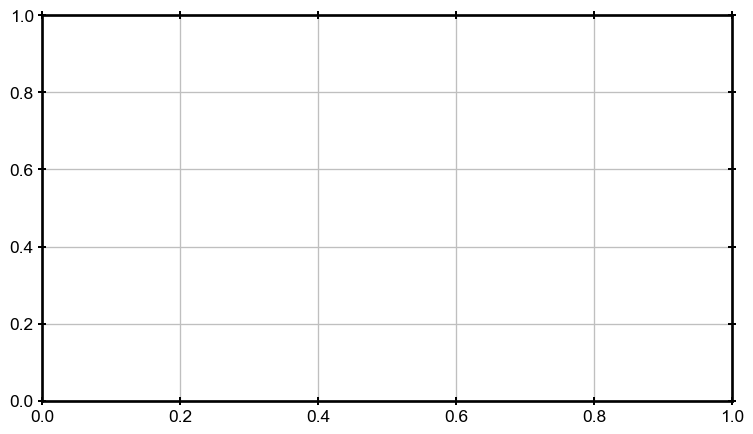

In [8]:
species = "e_aq"
with fig_man.open(f"jacobian evolution for {species}") as (fig, ax):
    for col, s in df_j.xs(species, level="sp", axis=1).items():
        if s.sum() == 0.0:
            continue
        ax.semilogx(s.index, s, label=col, marker="")
    RPlot.set_legend_right(ax)
        

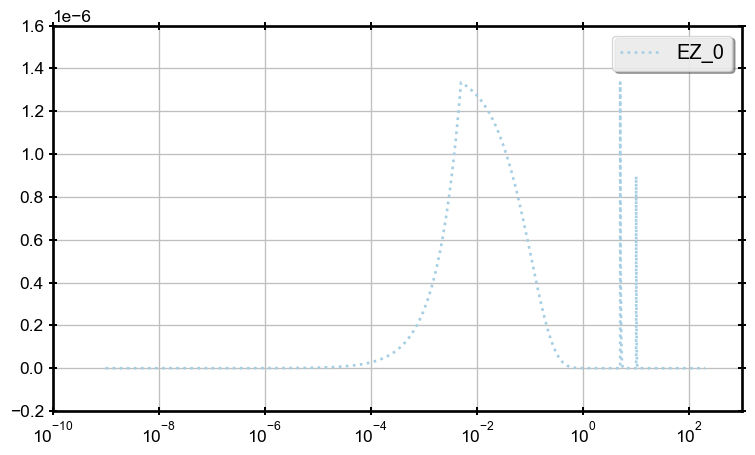

In [9]:
species = "EZ_0"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rate EZ0") as (fig, ax):
    ax.semilogx(df_r.index, df_r[species], label=f"EZ_0", marker="", linestyle=":")
    ax.legend()

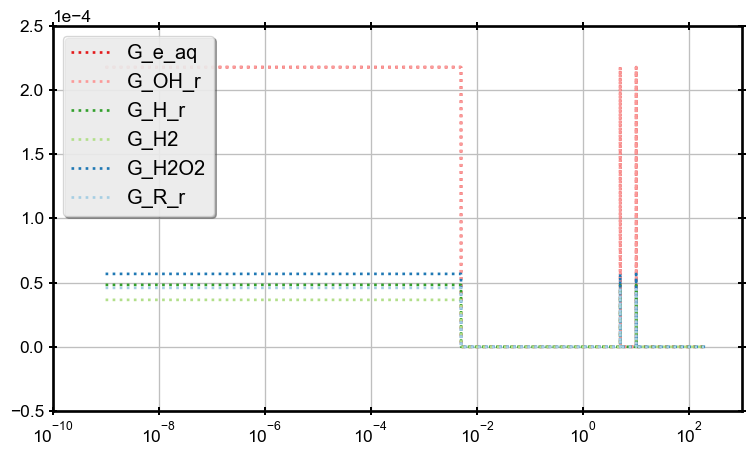

In [10]:
reac = ["G_e_aq", "G_OH_r", "G_H_r", "G_H2", "G_H2O2", "G_R_r"]
fig_man.set_brewer_map("Paired", "qualitative", len(reac), reverse=True)
with fig_man.open(f"Radiolytic reactions") as (fig, ax):
    for label in reac:
        ax.semilogx(df_r.index, df_r[label], label=label, marker="", linestyle=":")
    ax.legend()

### Plot reaction rates by species

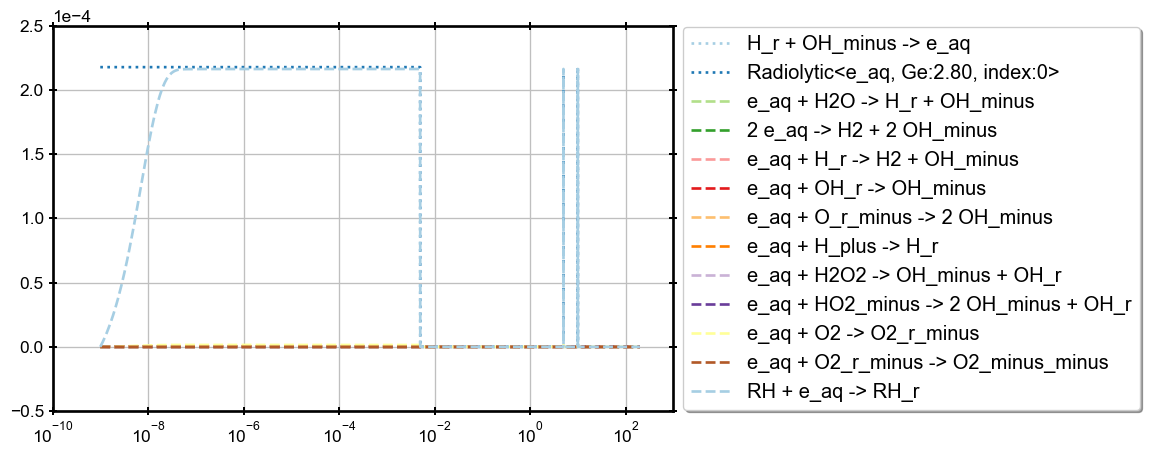

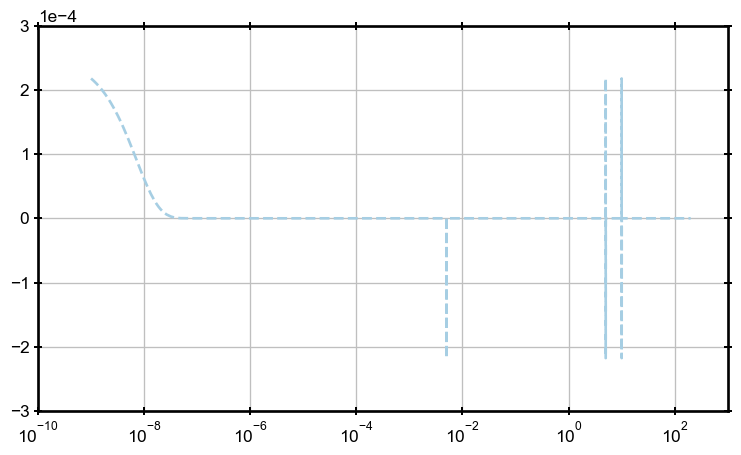

In [11]:
species = "e_aq"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

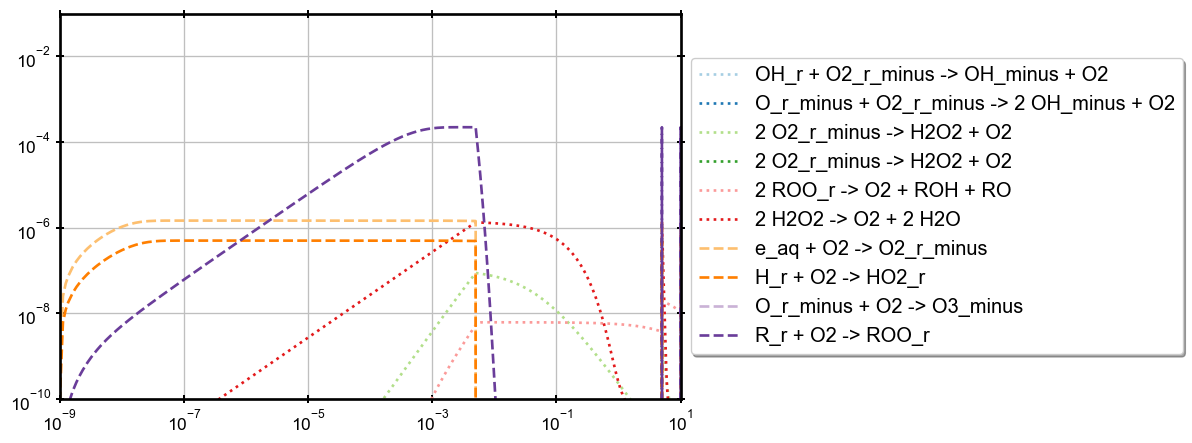

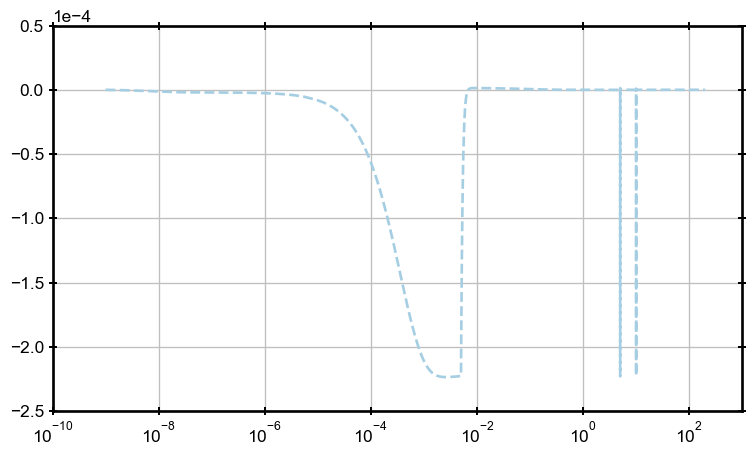

In [12]:
species = "O2"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle="--")
    ax.set_ylim(bottom=1e-10)
    ax.set_xlim([1e-9, 10])
    RPlot.set_legend_right(ax)
    
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

NameError: name 'df' is not defined

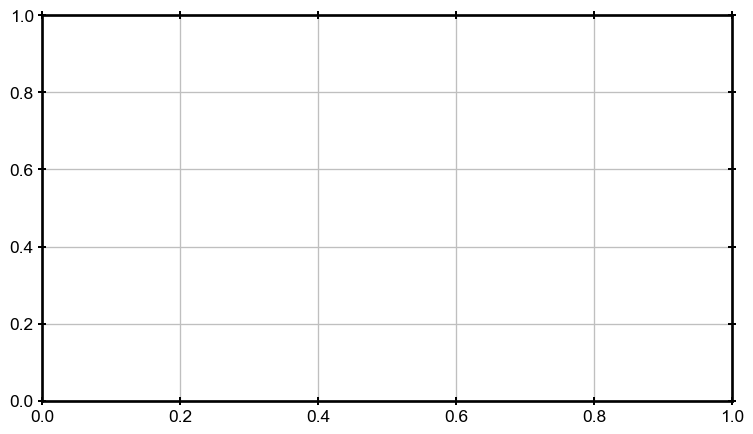

In [13]:
species = "OH_minus"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)

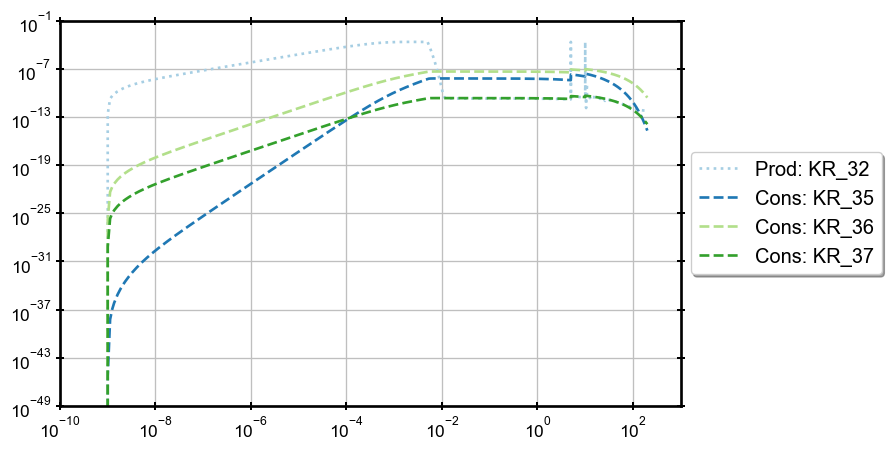

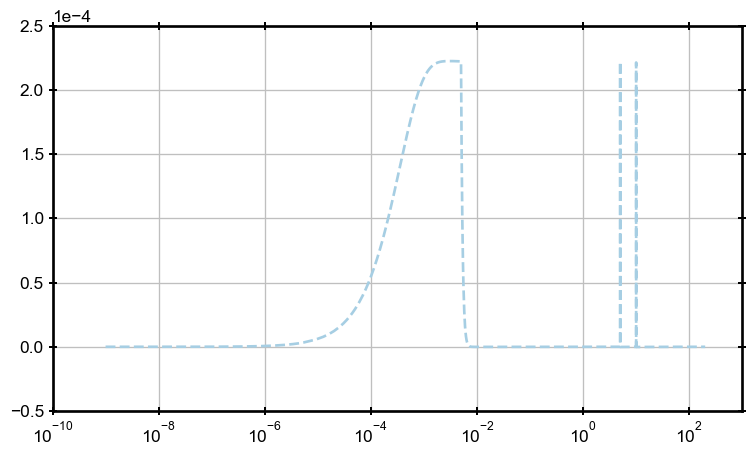

In [17]:
species = "ROO_r"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df_r.index, df_r[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df_r.index, df_r[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

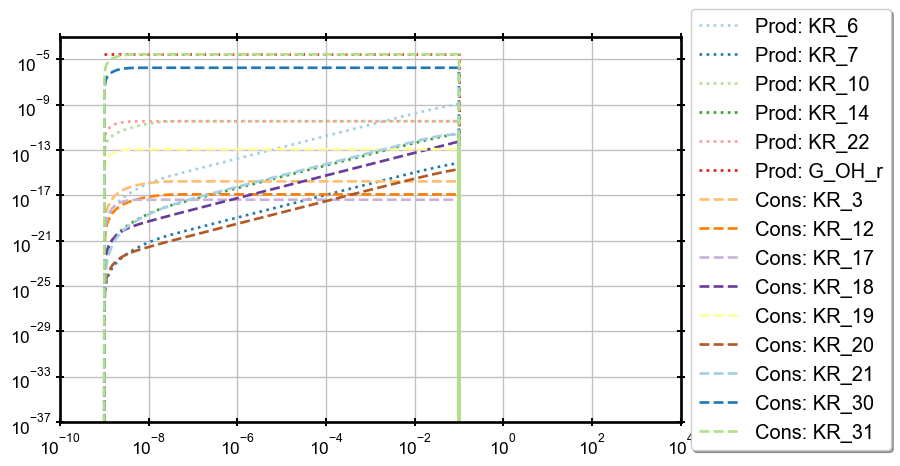

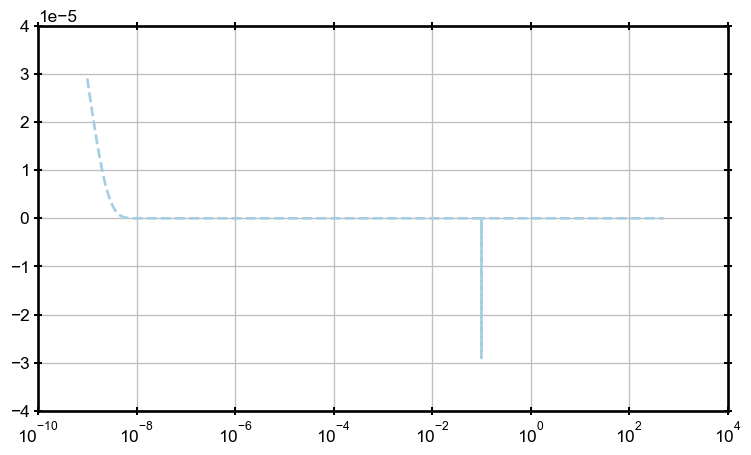

In [16]:
species = "OH_r"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

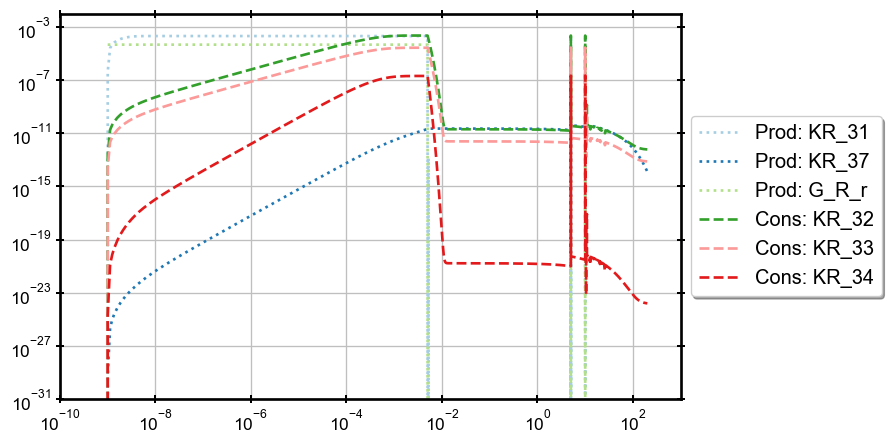

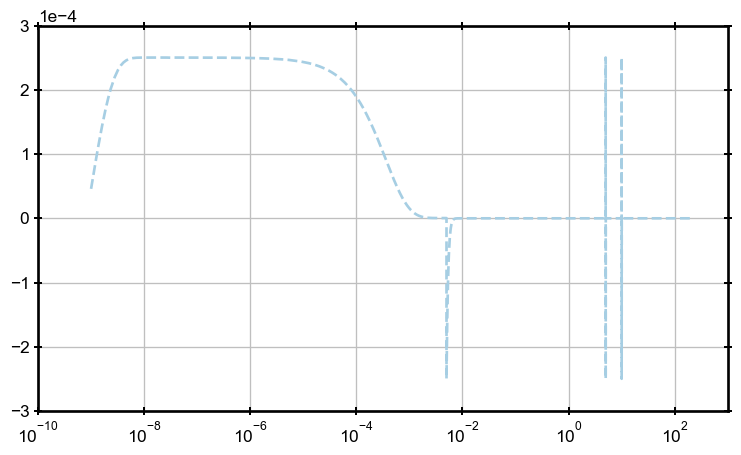

In [18]:
species = "R_r"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df_r.index, df_r[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df_r.index, df_r[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

### Acid/Base

In [23]:
part = env.reactions.acid_base[2].compute_partition(1, 1e-7)
1/ (part.dHA / part.dA)

125.89254117941663

## Debug Enzimatic reactions

Enzi matrices:  
1. Ez_substrate VECTOR ==> substrate selection  
1. Ez_enzyme    VECTOR ==> Enzyme selection  
1. Ez_kmki      MATRIX ==> Line 0: K micha, Line 1: k_value 

Error is 
> Mismatch dimensions  
> Line: beta = np.matmul(Enzi[2][0, :] * Enzi[2][1, :], Enzi[0])

In [10]:
y0[10] = 4

In [14]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y0, Enzi[0])
KK = np.prod(Enzi[2], axis=0)

array([72820000.])

In [20]:
Enzi[2][1,:] * E * S 

array([21184000.])

In [21]:
MM = Enzi[2][1, :] * E * S / (Enzi[2][0, :] + S)
MM

array([4153725.49019608])

In [22]:
np.matmul(Enzi[0], MM)

array([      0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        , 4153725.49019608,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ])

 ## Debug Jacobian

In [140]:
list(sim.env.species.iter_cst_species())

[CstSpecies<H2O, cc=6e+01, index= 3>,
 CstSpecies<catalase, cc=4, index= 4>,
 CstSpecies<H_plus, cc=1e-07, index= 5>,
 CstSpecies<OH_minus, cc=1e-07, index= 6>]

In [137]:
cst_sp

array([5.5e+01, 1.0e-07, 1.0e-07, 0.0e+00])

In [141]:
for elt in sim.env.iter_DynSpecies():
    print(elt)

SimSpecies<e_aq, index=0>
SimSpecies<H_r, index=1>
SimSpecies<H2, index=2>


In [121]:
y = np.array([3,2,1])
jac = jacobian(0,y,sim.beam, **sim.mat)
matprint(jac)

   -550  -3.6e-10  0  
    550  -1.8e-10  0  
2.4e-10   1.8e-10  0  


In [144]:
cst_sp, AB_mat, Ki_mat, Gi_mat, Ez_mat = sim.mat["cst_sp"], sim.mat["AB_mat"], sim.mat["Ki_mat"], sim.mat["Gi_mat"], sim.mat["Ez_mat"]
yy = np.append(y, cst_sp)
yy[3] = 1
yy

array([3.e+00, 2.e+00, 1.e+00, 1.e+00, 4.e+00, 1.e-07, 1.e-07])

1) Check Ki_mat[3]

In [45]:
for sp in sim.env.iter_DynSpecies():
    print(f"Species: d/d{sp.label}")
    for idx in range(Ki_mat[3].shape[2]):
        matprint(Ki_mat[3][:,:,idx, sp.index])
        print()

Species: d/de_aq
0  2  
0  0  
0  0  
1  0  
0  0  
0  0  

nan  0  
nan  1  
nan  0  
nan  0  
nan  0  
nan  0  

nan  nan  
nan  nan  
nan  nan  
nan  nan  
nan  nan  
nan  nan  

Species: d/dH_r
0  1  
0  0  
0  0  
0  0  
0  0  
0  0  

0  1  
0  0  
0  0  
0  0  
0  0  
0  0  

0  nan  
0  nan  
0  nan  
0  nan  
0  nan  
0  nan  

Species: d/dH2
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  

0  0  
0  0  
0  0  
0  0  
0  0  
0  0  

0  0  
0  0  
0  0  
0  0  
0  0  
0  0  



2. Check jacobian calc

In [93]:
yy = np.append(y, cst_sp)
yy[3] = 1

In [94]:
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", yy, Ki_mat[3]), nan=1)
for sp in sim.env.iter_species():
    print(f"Species: d/d{sp.label}")
    matprint(res[:,:,sp.index])
    print()

Species: d/de_aq
1  1  1  
6  2  1  

Species: d/dH_r
0  0  0  
3  3  1  

Species: d/dH2
0  0  0  
0  0  0  

Species: d/dH2O
0  0  0  
0  0  0  

Species: d/dH_plus
0  0  0  
0  0  0  

Species: d/dOH_minus
0  0  0  
0  0  0  



In [95]:
res = np.prod(res, axis=1).T * Ki_mat[0]
np.matmul(Ki_mat[1], res.T)

array([[-490., -360.,    0.,    0.,    0.,    0.],
       [-230., -180.,    0.,    0.,    0.,    0.],
       [ 240.,  180.,    0.,    0.,    0.,    0.],
       [   0.,    0.,    0.,    0.,    0.,    0.],
       [   0.,    0.,    0.,    0.,    0.,    0.],
       [   0.,    0.,    0.,    0.,    0.,    0.]])

OK.
Now check Enzymatic contrib

In [153]:
E = np.matmul(yy, Ez_mat[1])
S = np.matmul(yy, Ez_mat[0]) + Ez_mat[2][0, :]
JEnzi = np.prod(Ez_mat[2], axis=0) * E / S / S
JEnzi = np.multiply(Ez_mat[0], JEnzi[None, :])

In [157]:
matprint(np.matmul(Ez_mat[3], JEnzi.T))

0         0  0  0  0  0  0  
0  -2.28928  0  0  0  0  0  
0   2.28928  0  0  0  0  0  
0         0  0  0  0  0  0  
0         0  0  0  0  0  0  
0         0  0  0  0  0  0  
0         0  0  0  0  0  0  


In [162]:
Jab = AB_mat[0] + AB_mat[2].sum(axis=1)
AB_mat[2]

array([], shape=(7, 0), dtype=float64)

In [18]:
y = np.array(np.arange(2,31))
for sp in sim.env.species:
    print(f"{sp.index:02d}) {sp.label} {' '*(15-len(sp.label))} = {y[sp.index]:.2g}")

00) OH_r             = 2
01) O_r_minus        = 3
02) H2O2             = 4
03) HO2_minus        = 5
04) HO2_r            = 6
05) O2_r_minus       = 7
06) e_aq             = 8
07) H_r              = 9
08) H2               = 10
09) O2               = 11
10) O2_minus_minus   = 12
11) O3_minus         = 13
12) Fe_plus_plus_plus  = 14
13) HO_r             = 15
14) RH_r             = 16
15) R_r              = 17
16) ROO_r            = 18
17) ROH              = 19
18) RO               = 20
19) ROOH             = 21
20) H2O              = 22
21) catalase         = 23
22) Fe_plus_plus     = 24
23) GSH              = 25
24) RH               = 26
25) unsat_lipid      = 27
26) H_plus           = 28
27) OH_minus         = 29
28) trash            = 30


In [34]:
y = np.append(sol.y[:,100], sim.mat["cst_sp"])
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, sim.mat["Ki_mat"][3]), nan=1)
res = np.prod(res, axis=1).T * sim.mat["Ki_mat"][0][None,:]
res = np.matmul(sim.mat["Ki_mat"][1], res.T)

In [35]:
matprint(res)

-1.06504e+09       9.9e+07     22.7044   5.16226         0      -2.17991    1.5518e+06       13244.6  -0.0114445             0  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
         4.2  -1.80097e+11           0         0         0  -2.05825e-06  -7.54693e-05             0           0  -1.23495e-05  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
     2.99737             0    -22.7044         0   6.35972       9796.16  -1.55179e+06      -12307.5           0             0  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
    -21.1107             0           0  -9.24958         0             0      -9.85166             0           0             0  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
     21.1107             0           0   2.04366  -6.35972             0             0   1.04999e+12           0       13.3554  0  0  0  0  0             0         0  0  0  0  0  0  0 

In [ ]:

res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, ki_mat[3]), nan=1)
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    matprint(res[:,:,sp.index])
    print()

e_aq
 2  1  
22  1  
12  1  
 5  1  
 6  1  
 3  1  
 7  1  
 8  1  
14  1  
10  1  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  



In [ ]:
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    for _ in range(ki_mat[3].shape[2]):
        matprint(ki_mat[3][:,:,_,sp.index])
        print()

e_aq
1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0

## Enzimatic contrib

In [66]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y, Enzi[0]) + Enzi[2][0,:]
JEnzi = np.prod(Enzi[2], axis=0) * E / S / S # Vector...
np.multiply(Enzi[0], JEnzi[None,:])

array([[    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [33946.73970048],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ]])

In [41]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y, Enzi[0]) + Enzi[2][0,:]
JEnzi = np.prod(Enzi[2], axis=0) * E / S / S # Vector...
JEnzi = np.multiply(Enzi[0], JEnzi)
JEnzi = np.matmul(Enzi[3], JEnzi.T)
print(JEnzi.shape)
matprint(JEnzi)

(29, 29)
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  -67893.5  0

In [57]:
Jab = ab_mat[0] + ab_mat[2].sum(axis=1)
matprint(np.multiply(JEnzi, Jab[None,:]))

0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  -67892.1  0  0  0  0

In [58]:
ab_mat[0] + ab_mat[2].sum(axis=1)

array([1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       9.99987411e-01, 1.25890956e-05, 9.99980048e-01, 1.99522251e-05,
       7.88068385e-03, 9.92119316e-01, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00])

In [61]:
ab_mat[2]

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [9.99987411e-01, 0.00000000e+00, 0.00000000e+00],
       [1.25890956e-05, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 9.99980048e-01, 0.00000000e+00],
       [0.00000000e+00, 1.99522251e-05, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 7.88068385e-03],
       [0.00000000e+00, 0.00000000e+00, 9.92119316e-01],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000